# Dopamine mice: photometry and wheel, from habituation to the end of training
Oct 2026 \
author: Inês Laranjeira (drafted with Claude)

**Purpose.** The DA proposal in `../README.md` needs, per session, the **continuous** DA signal and the **wheel**. This notebook lists what exists for every DAT-Cre mainenlab mouse, session by session, from habituation through training (and the biased/ephys sessions after it).

**Source.** `da_inventory_sessions.csv` / `da_inventory_mice.csv` (`da_inventory.py`, an Alyx query, 27 Oct 2026):
* **DA** = the processed continuous signal `alf/photometry/photometry.signal.pqt`.
* **wheel** = the extracted `_ibl_wheel.position.npy`. **raw wheel** = only the rig's encoder log `_iblrig_encoderPositions.raw.ssv`. Habituation sessions have only the raw log: the wheel moves nothing during habituation, and the IBL extractor doesn't produce a wheel for it. It can be extracted from the raw log, but it has to be put on the session clock ourselves.
* **Protocol** from the session's task protocol: habituation / training (trainingChoiceWorld, including the `_NPH_` variants) / biased / ephys / passive / other (no task protocol, or histology).

Not checked here: photometry signal quality.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / 'paper-individuality'))
sys.path.insert(0, str(REPO / 'representation_learning' / 'dopamine'))
import paper_style as ps
import da_data as dd
ps.use('paper')
pd.set_option('display.width', 220)

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## 1. How many mice have DA + wheel?

Per mouse: habituation sessions with DA (and the raw wheel), training sessions with DA + the extracted wheel, the first training session that has both, and the biased/ephys sessions with both. Only mice with DA in at least one session.

In [2]:
T = dd.session_table()
sessions, mice = dd.load_inventory()
T['da_wheel'] = T['signal'] & T['wheel']
T['da_raw_wheel'] = T['signal'] & T['raw_wheel']

def per_mouse(g):
    hab, tr = g[g['session_class'] == 'habituation'], g[g['session_class'] == 'training']
    post = g[g['session_class'].isin(['biased', 'ephys'])]
    first = tr.loc[tr['da_wheel'], 'training_ordinal']
    return pd.Series(dict(
        target=g['target'].iloc[0], first_training=tr['date'].min(),
        hab=len(hab), hab_da_rawwheel=int(hab['da_raw_wheel'].sum()),
        training=len(tr), training_da_wheel=int(tr['da_wheel'].sum()),
        first_da_wheel_session=int(first.min()) if len(first) else np.nan,
        biased_ephys_da_wheel=int(post['da_wheel'].sum()),
        reached_biased=bool((g['session_class'] == 'biased').any())))

M = T.groupby('subject').apply(per_mouse)
M = M[(M['hab_da_rawwheel'] + M['training_da_wheel'] + M['biased_ephys_da_wheel']) > 0]
M['coverage'] = (M['training_da_wheel'] / M['training']).round(2)
M['cohort'] = np.where(M['first_training'] < '2024', '2021-22', '2025-26')
M['area'] = M['target'].str[:3]
M = M.sort_values(['cohort', 'area', 'training'], ascending=[False, False, False])
print(M.drop(columns=['area']).to_string())

          target first_training  hab  hab_da_rawwheel  training  training_da_wheel  first_da_wheel_session  biased_ephys_da_wheel  reached_biased  coverage   cohort
subject                                                                                                                                                             
ZFM-08828    VTA     2025-05-20    3                3        69                 63                     1.0                     41            True      0.91  2025-26
ZFM-08818    VTA     2025-05-20    3                3        66                 61                     1.0                     37            True      0.92  2025-26
ZFM-08827    VTA     2025-05-20    3                3        65                 57                     1.0                      0           False      0.88  2025-26
ZFM-09044    VTA     2025-07-28    3                3        65                 57                     1.0                     34            True      0.88  2025-26
ZFM-08488 

/tmp/ipykernel_9715/1769228723.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  M = T.groupby('subject').apply(per_mouse)


In [3]:
full = M[(M['first_da_wheel_session'] <= 2) & (M['coverage'] >= 0.7)]
print(f"mice with DA + wheel in any training session: {(M['training_da_wheel'] > 0).sum()} "
      f"(VTA {((M['training_da_wheel'] > 0) & (M['area'] == 'VTA')).sum()}, SNc {((M['training_da_wheel'] > 0) & (M['area'] == 'SNc')).sum()})")
print(f"... from training session 1-2 and covering >= 70 % of training: {len(full)} "
      f"(VTA {(full['area'] == 'VTA').sum()}, SNc {(full['area'] == 'SNc').sum()})")
print(f"   of which reached biased: VTA {((full['area'] == 'VTA') & full['reached_biased']).sum()}, "
      f"SNc {((full['area'] == 'SNc') & full['reached_biased']).sum()}")
print(f"mice with DA + raw wheel in habituation: {(M['hab_da_rawwheel'] > 0).sum()}; "
      f"in every habituation session: {(M['hab_da_rawwheel'] == M['hab']).sum()}")
print(f"DA + wheel sessions in total: habituation {M['hab_da_rawwheel'].sum()} (raw wheel), "
      f"training {M['training_da_wheel'].sum()}, biased/ephys {M['biased_ephys_da_wheel'].sum()}")

mice with DA + wheel in any training session: 22 (VTA 10, SNc 12)
... from training session 1-2 and covering >= 70 % of training: 14 (VTA 6, SNc 8)
   of which reached biased: VTA 4, SNc 4
mice with DA + raw wheel in habituation: 19; in every habituation session: 11
DA + wheel sessions in total: habituation 52 (raw wheel), training 672, biased/ephys 334


## 2. Session by session

One row per mouse, one column per session in date order. The x axis is aligned so that **session 1 = the first training session**: habituation sits at negative numbers, biased/ephys after the last training session.
* **Upper band (colour) = data.** Dark blue: DA + extracted wheel. Light blue: DA + raw wheel only (habituation). Sand: DA without any wheel. Grey: no DA.
* **Lower strip = protocol.** Habituation, training, biased, ephys, passive, other.

Mice sorted by cohort, target and number of training sessions; ✓ = reached biased.

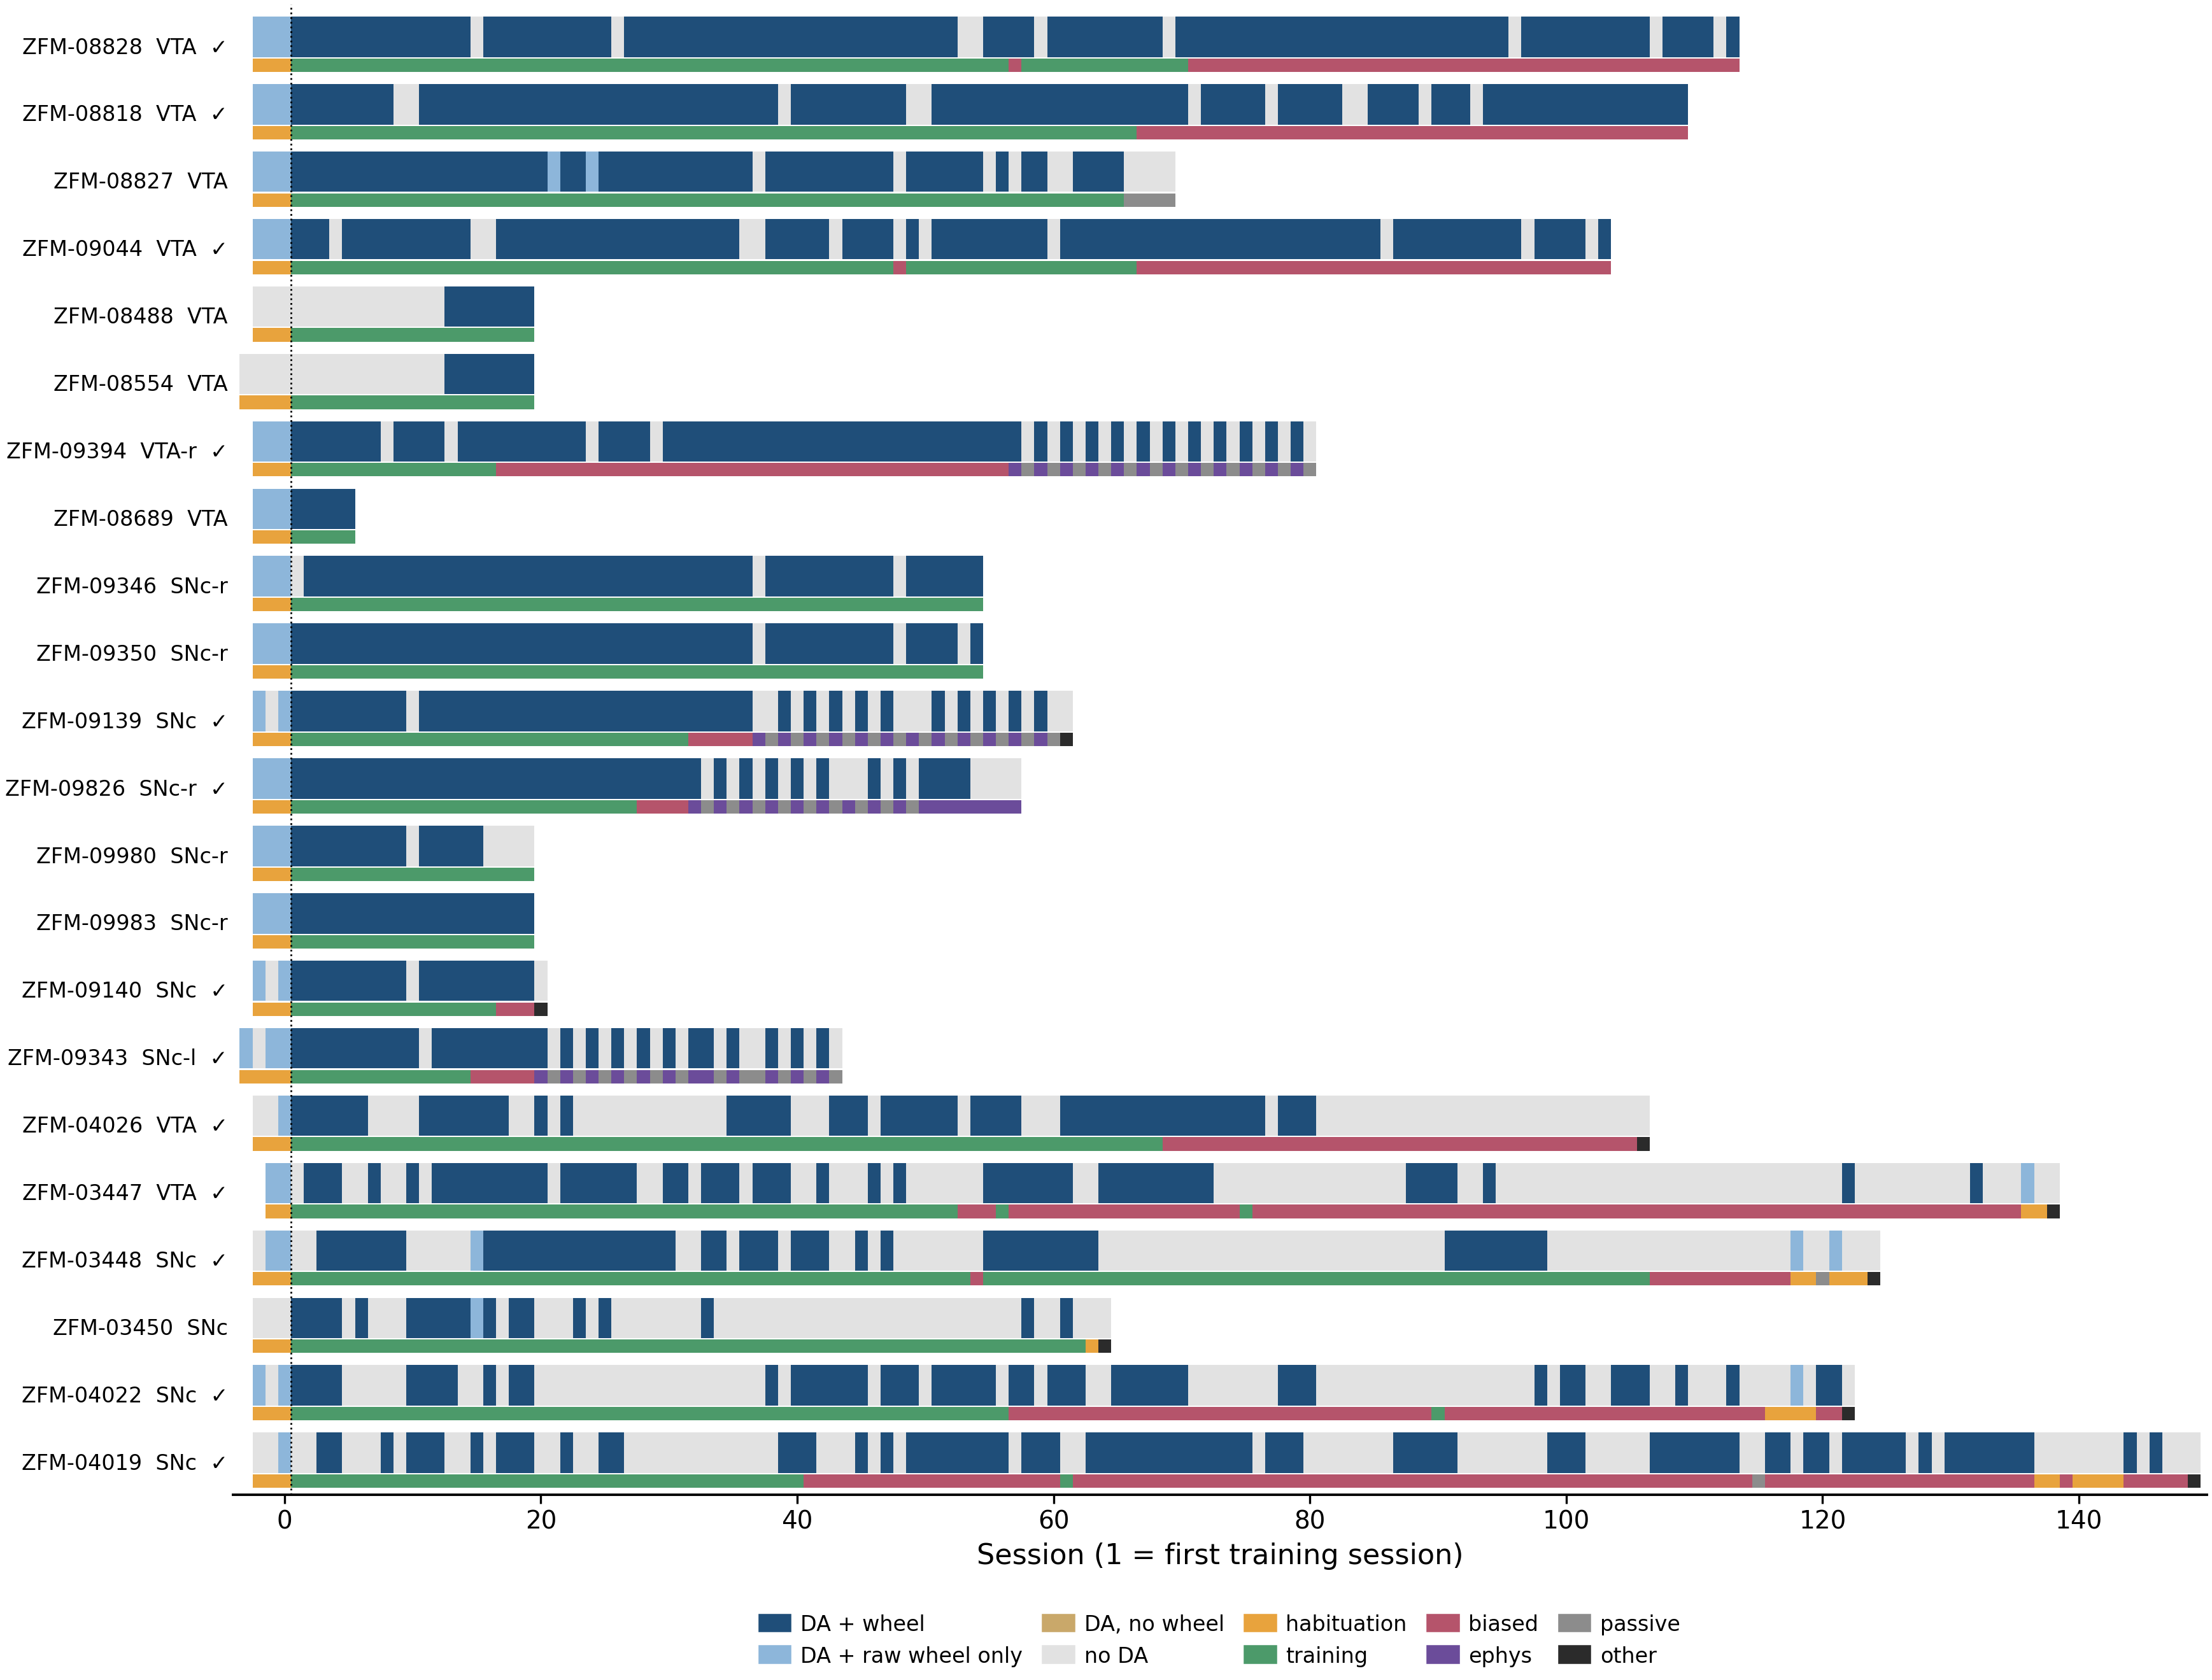

In [4]:
DATA_COL = {'da_wheel': '#1F4E79', 'da_raw_wheel': '#8DB6DA', 'da_only': '#C9A86A', 'none': '#E2E2E2'}
DATA_LAB = {'da_wheel': 'DA + wheel', 'da_raw_wheel': 'DA + raw wheel only', 'da_only': 'DA, no wheel', 'none': 'no DA'}
PROT_COL = {'habituation': '#E8A33D', 'training': '#4C9A6A', 'biased': '#B5546B', 'ephys': '#6B4C9A',
            'passive': '#8C8C8C', 'other': '#2B2B2B'}

def data_state(r):
    if not r['signal']:
        return 'none'
    if r['wheel']:
        return 'da_wheel'
    return 'da_raw_wheel' if r['raw_wheel'] else 'da_only'

D = T[T['subject'].isin(M.index)].copy()
D['state'] = D.apply(data_state, axis=1)
D = D.sort_values(['subject', 'date', 'number'])
D['pos'] = D.groupby('subject').cumcount()
first_tr = D[D['session_class'] == 'training'].groupby('subject')['pos'].min()
D['x'] = D['pos'] - D['subject'].map(first_tr) + 1                  # first training session = 1

order = list(M.index)
fig, ax = plt.subplots(figsize=(10, 0.3 * len(order) + 1))
for i, s in enumerate(order):
    g = D[D['subject'] == s]
    for x, st, pc in zip(g['x'], g['state'], g['session_class']):
        ax.add_patch(Rectangle((x - 0.5, i - 0.42), 1, 0.6, color=DATA_COL[st], lw=0))
        ax.add_patch(Rectangle((x - 0.5, i + 0.2), 1, 0.2, color=PROT_COL[pc], lw=0))
ax.set_xlim(D['x'].min() - 1, D['x'].max() + 1)
ax.set_ylim(len(order) - 0.5, -0.6)
ax.axvline(0.5, color='k', lw=0.5, ls=':')
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{s}  {M.loc[s, 'target']}{'  ✓' if M.loc[s, 'reached_biased'] else ''}" for s in order], fontsize=6)
ax.set_xlabel('Session (1 = first training session)')
for sp in ['left', 'top', 'right']:
    ax.spines[sp].set_visible(False)
ax.tick_params(axis='y', length=0)
h1 = [Patch(color=DATA_COL[k], label=DATA_LAB[k]) for k in DATA_COL]
h2 = [Patch(color=PROT_COL[k], label=k) for k in PROT_COL]
ax.legend(handles=h1 + h2, frameon=False, fontsize=6, ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.07))
plt.show()

## Summary

1. **22 mice have DA + wheel in training (10 VTA, 12 SNc), 672 training sessions in all.** 14 of them are covered from training session 1–2 with ≥ 70 % of their training sessions (6 VTA, 8 SNc), all from the 2025–26 cohort:
   * VTA that reached biased: ZFM-08818, 08828, 09044 (65–69 training sessions, slow) and 09394 (16, fast).
   * VTA that didn't: ZFM-08827 (65 training sessions, never biased) and ZFM-08689 (stopped after 5).
   * SNc that reached biased: ZFM-09139, 09140, 09343, 09826. SNc that didn't: ZFM-09346, 09350 (54 sessions each), and 09980, 09983 (19, recent).
   * The 2021–22 cohort (6 mice) has DA + wheel in only 29–60 % of training sessions. ZFM-08488 and 08554 start at training session 13.
2. **Habituation has DA too, but only the raw wheel.** 52 habituation sessions in 19 mice have the DA signal. None has an extracted wheel; all of them have the rig's raw encoder log. Every 2025–26 mouse has DA in all or all but one of its 3–4 habituation sessions, except ZFM-08488 and 08554 (none). Using habituation means extracting the wheel from `_iblrig_encoderPositions.raw.ssv` and syncing it to the photometry ourselves.
3. **After training:** 334 biased/ephys sessions have DA + wheel, so the same mice can be followed past criterion (e.g. ZFM-09394: 16 training + ~40 biased).
4. **Protocol quirks visible in the plot:** a few biased sessions sit in the middle of training (ZFM-08828, 09044), some older mice have habituation sessions again late on, and ZFM-08827 has two training sessions with only the raw wheel.

**For the DA analysis:** the core set is the 2025–26 mice with DA + wheel from the first training session: 5 VTA mice with full training (4 learners + the non-learner ZFM-08827) and 8 SNc mice. Habituation adds a pre-task baseline (3 sessions per mouse) once its wheel is extracted. The video appendix below is kept for reference.


## Appendix: video and Lightning Pose (the collaborators' sheet)

* **LP status** in the sheet matches Alyx exactly (TRUE ⇔ `lightningPose.pqt` exists).
* **Video QC** (IBL's left-camera checks) is in the sheet for most 2025–26 training sessions, also where LP hasn't been run. It is what decides which sessions are worth running LP on.
* The **LP QC** columns (wheel × paw cross-correlation `peak_val_*`, `drift`; event-triggered movement) exist only where LP was run.

In [5]:
tr = T[T['session_class'] == 'training']
S = tr[tr['signal'] & tr['subject'].isin(M.index)]
print('training sessions with signal:', len(S), '| listed in the sheet:', S['in_sheet'].sum(),
      '| LP run:', S['lightning_pose'].sum())
print(pd.crosstab(S['LP status'].fillna('not in sheet'), S['lightning_pose'], margins=True), '\n')
qc = S[S['in_sheet']][dd.VIDEO_QC].apply(lambda c: c.value_counts()).reindex(dd.QC_ORDER).fillna(0).astype(int)
print('video QC outcomes, training sessions with signal that the sheet lists:')
print(qc.to_string())

training sessions with signal: 676 | listed in the sheet: 466 | LP run: 111
lightning_pose  False  True  All
LP status                       
FALSE             376     0  376
TRUE                0    90   90
not in sheet      189    21  210
All               565   111  676 

video QC outcomes, training sessions with signal that the sheet lists:
          qc_videoLeft_timestamps  qc_videoLeft_dropped_frames  qc_videoLeft_pin_state  qc_videoLeft_focus  qc_videoLeft_position  qc_videoLeft_brightness  qc_videoLeft_resolution  qc_videoLeft_wheel_alignment
PASS                          462                          442                     264                 373                    450                       60                      462                           258
WARNING                         0                           15                     197                   0                     12                      296                        0                           191
FAIL                   

### Usable video, per mouse

A session counts as **video usable** when the checks that matter for pose estimation pass: timestamps PASS, dropped frames not FAIL/CRITICAL, focus PASS and position not FAIL. Brightness is left out: it is WARNING/FAIL in most sessions (dark training rigs) and LP has run fine on many of those. Only sessions the sheet lists can be judged.

In [6]:
def video_ok(r):
    return (r['qc_videoLeft_timestamps'] == 'PASS'
            and r['qc_videoLeft_dropped_frames'] in ('PASS', 'WARNING')
            and r['qc_videoLeft_focus'] == 'PASS'
            and r['qc_videoLeft_position'] in ('PASS', 'WARNING'))
S = S.assign(video_ok=S.apply(video_ok, axis=1))
vid = (S.groupby('subject').agg(target=('target', 'first'), signal=('eid', 'size'), in_sheet=('in_sheet', 'sum'),
                                video_ok=('video_ok', 'sum'), focus_fail=('qc_videoLeft_focus', lambda c: (c == 'FAIL').sum()),
                                LP_run=('lightning_pose', 'sum'), video_qc_score=('video_qc_score', 'median'))
         .reindex([s for s in order if s in set(S['subject'])]))
print(vid.to_string())

          target  signal  in_sheet  video_ok  focus_fail  LP_run  video_qc_score
subject                                                                         
ZFM-08828    VTA      63        57        46          11      10           0.864
ZFM-08818    VTA      61        55        44          11       5           0.864
ZFM-08827    VTA      59        50        46           3       6           0.864
ZFM-09044    VTA      57        51        45           5      11           0.864
ZFM-08488    VTA       7         7         1           6       0             NaN
ZFM-08554    VTA       7         7         5           0       2           0.898
ZFM-09394  VTA-r      14        14        13           1       0           0.864
ZFM-08689    VTA       5         4         4           0       0           0.752
ZFM-09346  SNc-r      51        47        21          26       5           0.752
ZFM-09350  SNc-r      51        45        39           6       9           0.864
ZFM-09139    SNc      30    

### LP quality where it was run

`min_peak_val` = the smallest of the early/mid/late peak cross-correlations between LP paw speed and wheel speed (the QC used for the NM sessions, `NM_pose_qc_eids.csv`: `min_peak_corr`). Low values mean the paw tracking doesn't follow the wheel.

           LP_sessions  with_LP_QC  min_peak_val_median  below_0_3
subject                                                           
ZFM-03447            9           5             0.034065          3
ZFM-03448           15          13             0.088216          8
ZFM-03450            1           0                  NaN          0
ZFM-04019            3           2             0.328061          1
ZFM-04022           10           5             0.742795          0
ZFM-04026           17          11             0.696815          4
ZFM-08554            2           0                  NaN          0
ZFM-08818            5           1             0.636392          0
ZFM-08827            6           0                  NaN          0
ZFM-08828           10           0                  NaN          0
ZFM-09044           11           0                  NaN          0
ZFM-09139            3           0                  NaN          0
ZFM-09343            5           0                  NaN       

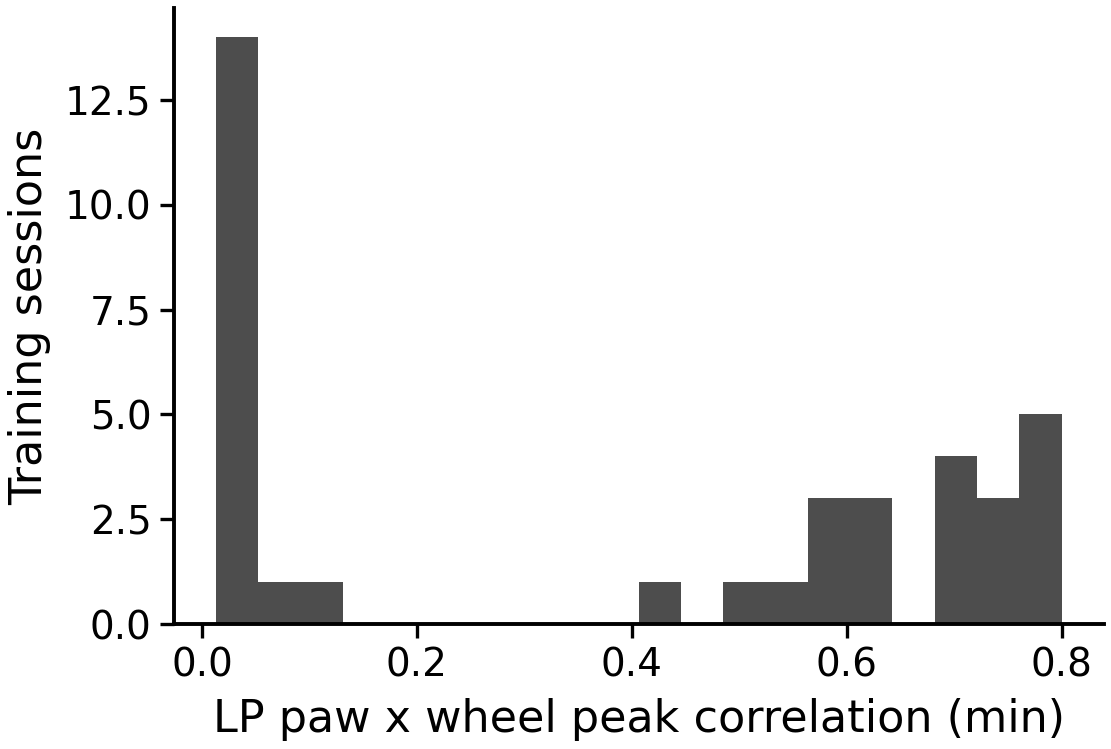

In [7]:
L = S[S['lightning_pose']]
print(L.groupby('subject').agg(LP_sessions=('eid', 'size'), with_LP_QC=('min_peak_val', 'count'),
                               min_peak_val_median=('min_peak_val', 'median'),
                               below_0_3=('min_peak_val', lambda v: (v < 0.3).sum())).to_string())
fig, ax = plt.subplots(figsize=(3, 2))
ax.hist(L['min_peak_val'].dropna(), bins=20, color='0.3')
ax.set_xlabel('LP paw x wheel peak correlation (min)'); ax.set_ylabel('Training sessions')
plt.show()